Generando reporte visual...


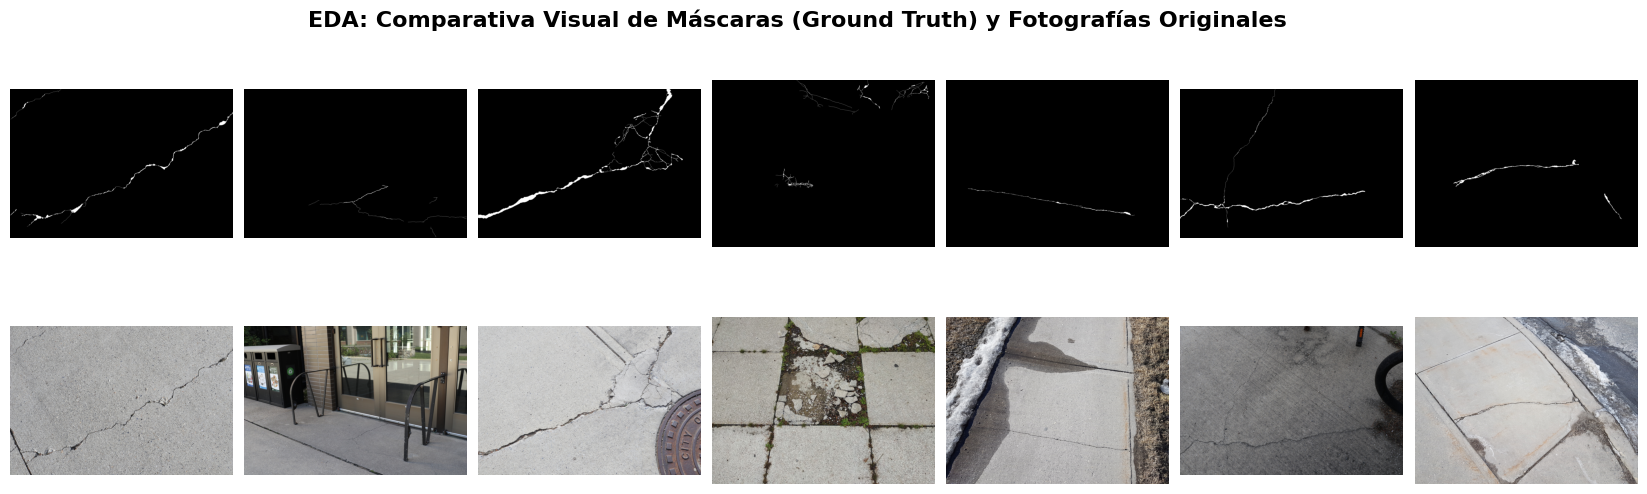

In [20]:
import os
import cv2
import random
import matplotlib.pyplot as plt
from glob import glob

def generar_reporte_visual_eda(ruta_base_dataset, num_muestras=7):

    ruta_imagenes = os.path.join(ruta_base_dataset, 'img')
    ruta_mascaras = os.path.join(ruta_base_dataset, 'lbl')

    lista_imagenes = glob(os.path.join(ruta_imagenes, '*.*'))

    if not lista_imagenes:
        print(f" No se encontraron imágenes en {ruta_imagenes}")
        return

    num_muestras = min(num_muestras, len(lista_imagenes))
    muestras_seleccionadas = random.sample(lista_imagenes, num_muestras)

    fig, axes = plt.subplots(2, num_muestras, figsize=(num_muestras * 3, 6))

    # Reducir el espacio entre las imágenes
    plt.subplots_adjust(wspace=0.05, hspace=0.05)

    # Cargar y mostrar las imágenes
    for idx, img_path in enumerate(muestras_seleccionadas):
        # Obtener el nombre del archivo
        nombre_archivo = os.path.basename(img_path)
        nombre_base = os.path.splitext(nombre_archivo)[0]

        # Cargar la imagen original en formato RGB
        img_bgr = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        patron_mascara = os.path.join(ruta_mascaras, f"{nombre_base}.*")
        ruta_mascara_encontrada = glob(patron_mascara)

        # Fila 0: Mostrar la Máscara (Ground Truth)
        ax_mask = axes[0, idx]
        ax_mask.axis('off') # Ocultar ejes

        if ruta_mascara_encontrada:
            # Si la máscara existe, cargarla en escala de grises
            mascara = cv2.imread(ruta_mascara_encontrada[0], cv2.IMREAD_GRAYSCALE)
            ax_mask.imshow(mascara, cmap='gray')
        else:
            # Si no se encuentra la máscara, mostrar un fondo negro
            ax_mask.imshow(np.zeros((img_rgb.shape[0], img_rgb.shape[1]), dtype=np.uint8), cmap='gray')
            ax_mask.set_title("Máscara\nNo Encontrada", fontsize=8, color='red')

        # Fila 1: Mostrar la Fotografía Original
        ax_img = axes[1, idx]
        ax_img.imshow(img_rgb)
        ax_img.axis('off') # Ocultar ejes

    # Añadir un título general a la figura
    fig.suptitle('EDA: Comparativa Visual de Máscaras (Ground Truth) y Fotografías Originales', fontsize=16, fontweight='bold', y=0.95)

    # Mostrar la figura
    plt.show()


RUTA_DATASET_TRAIN = '/content/drive/MyDrive/proyecto/dataset0.1/CCSS/originalSize-noExternalData'

print("Generando reporte visual...")
generar_reporte_visual_eda(RUTA_DATASET_TRAIN, num_muestras=7)

In [5]:
!pip install -q ultralytics opencv-python-headless

import os
import cv2
import yaml
import math
import shutil
import numpy as np
import torch
from glob import glob
from google.colab import drive
from ultralytics import YOLO

drive.mount('/content/drive')

if torch.cuda.is_available():
    print(f"GPU detectada: {torch.cuda.get_device_name(0)}")
else:
    print("GPU no detectada. Habilita T4 GPU en las opciones de Colab.")

DATASET_ORIGEN = '/content/drive/MyDrive/proyecto/dataset0.1/CCSS/benchmarkingDatasets'
DATASET_YOLO = '/content/dataset_yolo'

splits_origen = {
    'train': os.path.join(DATASET_ORIGEN, 'train/noAugmentation-noPatch'),
    'val': os.path.join(DATASET_ORIGEN, 'validation'),
    'test': os.path.join(DATASET_ORIGEN, 'test')
}

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 10.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mounted at /content/drive
GPU detectada: Tesla T4


Ingeniería Morfológica Matemática (Generación de Polígonos)
Este script navega por las carpetas lbl, aplica la dilatación matemática a las fisuras finas y convierte el resultado a los archivos .txt que exige YOLO, guardando todo en el formato estándar dentro de /content/dataset_yolo/

procesar_split_forense()   
    Lee máscaras de 'lbl', aplica dilatación morfológica, extrae contornos
    y guarda en formato YOLO junto con las imágenes de 'img'.

In [6]:
def procesar_split_forense(nombre_split, ruta_origen, ruta_yolo):

    img_dir_origen = os.path.join(ruta_origen, 'img')
    lbl_dir_origen = os.path.join(ruta_origen, 'lbl')

    img_dir_yolo = os.path.join(ruta_yolo, nombre_split, 'images')
    lbl_dir_yolo = os.path.join(ruta_yolo, nombre_split, 'labels')

    os.makedirs(img_dir_yolo, exist_ok=True)
    os.makedirs(lbl_dir_yolo, exist_ok=True)

    # Buscar máscaras en formato jpg, png o tif
    mascaras = glob(os.path.join(lbl_dir_origen, "*.*"))
    anotaciones = 0

    for mask_path in mascaras:
        filename = os.path.basename(mask_path)
        nombre_base = os.path.splitext(filename)[0]

        # Buscar la imagen original correspondiente
        img_path = glob(os.path.join(img_dir_origen, f"{nombre_base}.*"))
        if not img_path: continue
        img_path = img_path[0]

        # Leer y Binarizar Máscara
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None: continue
        h, w = mask.shape
        _, thresh = cv2.threshold(mask, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

        # 2. Dilatación Morfológica
        kernel = np.ones((3, 3), np.uint8)
        thresh_dilatada = cv2.dilate(thresh, kernel, iterations=1)

        # 3. Extracción de contornos para YOLO
        contornos, _ = cv2.findContours(thresh_dilatada, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        txt_path = os.path.join(lbl_dir_yolo, f"{nombre_base}.txt")
        with open(txt_path, 'w') as f:
            for contorno in contornos:
                if cv2.contourArea(contorno) < 15: continue # Filtro de ruido

                contorno_norm = contorno.flatten().astype(float)
                contorno_norm[0::2] /= w # X
                contorno_norm[1::2] /= h # Y

                linea = "0 " + " ".join([f"{x:.6f}" for x in contorno_norm]) + "\n"
                f.write(linea)
                anotaciones += 1

        # 4. Copiar imagen al entorno de entrenamiento
        shutil.copy(img_path, os.path.join(img_dir_yolo, os.path.basename(img_path)))

    print(f"{nombre_split.upper()}: {anotaciones} polígonos morfológicos generados.")

# Procesar Train, Val y Test
for split, ruta in splits_origen.items():
    if os.path.exists(ruta):
        procesar_split_forense(split, ruta, DATASET_YOLO)
    else:
        print(f"Ruta no encontrada: {ruta}")

✅ TRAIN: 2401 polígonos morfológicos generados.
✅ VAL: 598 polígonos morfológicos generados.
✅ TEST: 820 polígonos morfológicos generados.


Creación de YAML y Entrenamiento (Domain-Aware Augmentation)
Inyectamos los hiperparámetros que simulan la física de la iluminación en la obra civil, asegurando que el modelo de borde alcance una alta generalización.


epochs=100 - Suficiente para que las métricas se estabilicen

In [9]:
import os

DATASET_YOLO = '/content/dataset_yolo'

yaml_content = f"""
path: {DATASET_YOLO}
train: train/images
val: val/images
test: test/images

names:
  0: Rajadura
"""

yaml_path = os.path.join(DATASET_YOLO, 'ccss_forense.yaml')
with open(yaml_path, 'w') as f:
    f.write(yaml_content)

print(f"Archivo YAML creado correctamente en: {yaml_path}")

# Configurar y Entrenar YOLOv11 Nano para Edge
from ultralytics import YOLO
import torch

modelo = YOLO("yolo11n-seg.pt")

print("Iniciando Entrenamiento con Aumento de Dominio...")
resultados = modelo.train(
    data=yaml_path,
    epochs=100,
    imgsz=640,
    batch=32,
    device=0 if torch.cuda.is_available() else 'cpu',
    patience=20,
    project='/content/drive/MyDrive/projecto/Runs',
    name='YOLOv11_CCSS_Run',

    # Feature Engineering Fotométrico
    hsv_h=0.015, hsv_s=0.6, hsv_v=0.5, # Simulación de clima y sombras
    perspective=0.001,                 # Simulación de ángulo del smartphone
    erasing=0.2, copy_paste=0.2, mixup=0.1
)

Archivo YAML creado correctamente en: /content/dataset_yolo/ccss_forense.yaml
Iniciando Entrenamiento con Aumento de Dominio...
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.2, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_yolo/ccss_forense.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.2, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.5, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, 

/usr/local/lib/python3.13/dist-packages/ultralytics/data/augment.py:1317: RuntimeWarning: divide by zero encountered in divide
  xy = xy[:, :2] / xy[:, 2:3]


     70/100         7G      1.296      1.783      1.343      1.257          0         76        640: 100% ━━━━━━━━━━━━ 23/23 1.3it/s 17.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.5s/it 4.6s
                   all        181        598      0.541      0.331      0.325      0.184      0.524      0.303      0.293      0.109

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
     71/100         7G      1.304      1.814      1.378      1.252          0        171        640: 100% ━━━━━━━━━━━━ 23/23 1.5it/s 15.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.4s/it 4.2s
                   all        181        598      0.563      0.331      0.335        0.2      0.572      0.301        0.3      0.119

      Epoch    G

Cálculo del Eje Medial y Gravedad ACI

Esta función recibe la predicción en píxeles generada por el modelo entrenado y la transforma en datos forenses físicos utilizando parámetros de la cámara.


Comité 224 del American Concrete Institute (ACI):

* Menor a 0.1 mm (Leve): Las microfisuras son normales en el concreto por la pérdida de humedad al secarse (retracción plástica). No afectan la estructura, solo la estética.

* Entre 0.1 mm y 0.3 mm (Moderada): A partir de los 0.1 mm, el agua de la lluvia y la humedad ambiental pueden empezar a entrar en la grieta. Requiere que un operario le haga seguimiento para ver si crece.

* Mayor a 0.3 mm (Severa / Crítica): Este es el "Límite Máximo Permisible" general. Si la grieta supera este grosor, el agua, el oxígeno y los cloruros penetran profundamente hasta llegar a las varillas de acero dentro del concreto, oxidándolas (corrosión). Cuando el acero se oxida, se expande y destruye la columna desde adentro.

evaluar_severidad_estructural()
   Convierte la máscara de segmentación de YOLO en ancho máximo de fisura (mm).

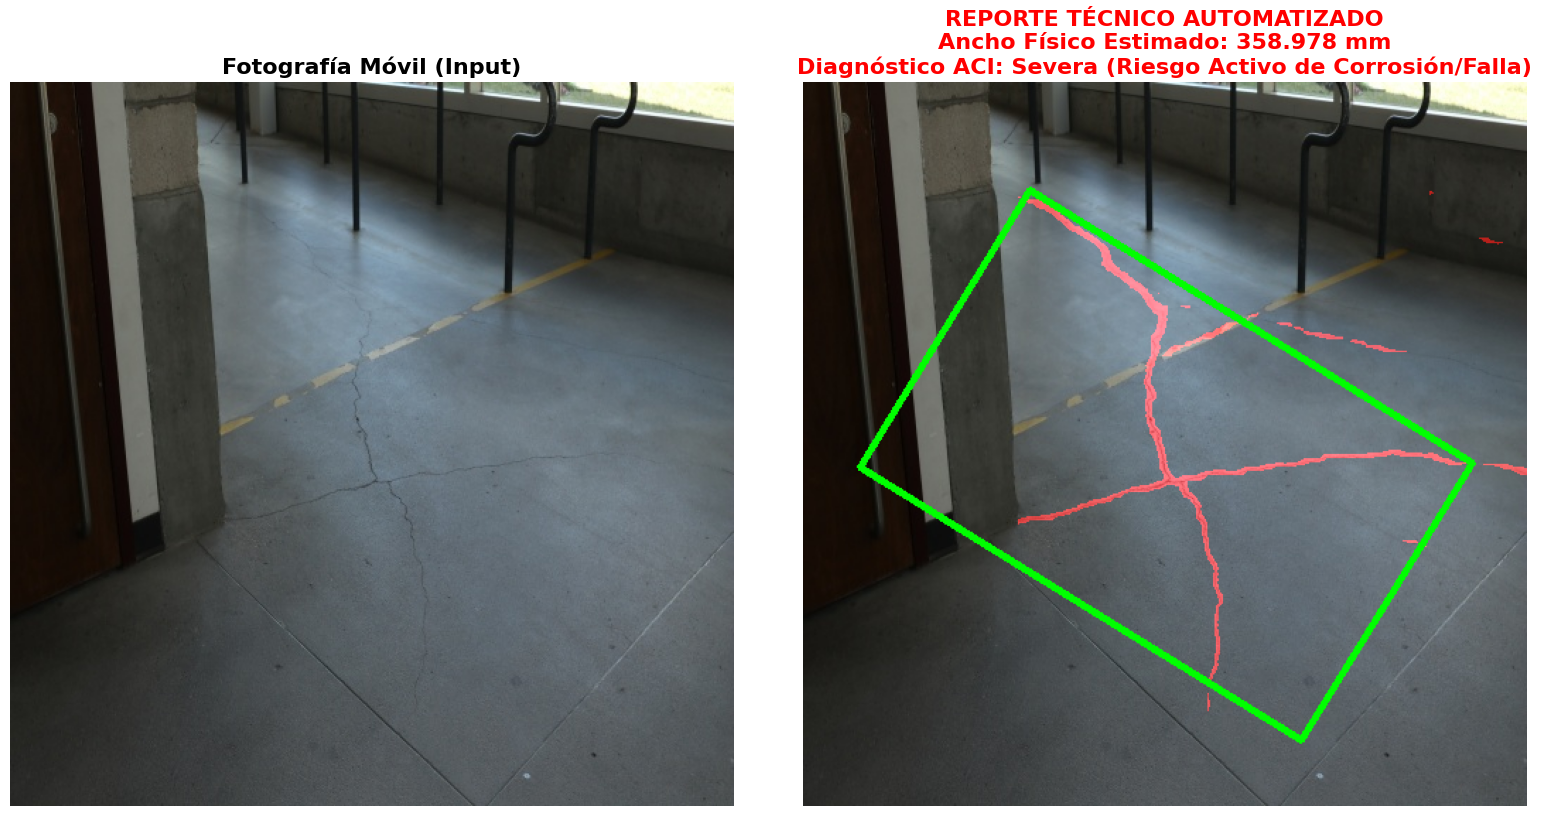

In [15]:
import os
import cv2
import math
import random
import numpy as np
from glob import glob
import matplotlib.pyplot as plt
from ultralytics import YOLO

def evaluar_severidad_estructural(mask_predict, focal_length_mm=4.0, dist_muro_mm=500.0, sensor_w_mm=6.4, img_w_px=640):

    mask_uint8 = (mask_predict * 255).astype(np.uint8)
    contornos, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contornos:
        return 0.0, "Sin daño estructural", None

    # Tomar la grieta más grande si hay varias desconectadas
    contorno_max = max(contornos, key=cv2.contourArea)
    rectangulo = cv2.minAreaRect(contorno_max)
    ancho_pixeles = min(rectangulo[1][0], rectangulo[1][1])

    # Fotogrametría P2M (Píxel a Milímetro)
    tamano_pixel_mm = sensor_w_mm / img_w_px
    magnificacion = focal_length_mm / dist_muro_mm
    grosor_mm = (ancho_pixeles * tamano_pixel_mm) / magnificacion

    # Catálogo ACI 224R-01
    if grosor_mm < 0.1:
        diagnostico = "Leve (Retracción capilar)"
    elif 0.1 <= grosor_mm < 0.3:
        diagnostico = "Moderada (Requiere monitoreo técnico)"
    else:
        diagnostico = "Severa (Riesgo Activo de Corrosión/Falla)"

    return grosor_mm, diagnostico, rectangulo

DATASET_YOLO = '/content/dataset_yolo'
imgs_prueba = glob(f"{DATASET_YOLO}/test/images/*.*")
if not imgs_prueba:
    imgs_prueba = glob(f"{DATASET_YOLO}/val/images/*.*")

img_ruta = random.choice(imgs_prueba)

ruta_pesos = '/content/drive/MyDrive/projecto/Runs/YOLOv11_CCSS_Run/weights/best.pt'
modelo_entrenado = YOLO(ruta_pesos)

# Inferencia
resultados = modelo_entrenado.predict(img_ruta, verbose=False)

# Preparar la imagen original para visualización
img_original = cv2.imread(img_ruta)
img_rgb = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)
img_overlay = img_rgb.copy()

grosor_final = 0.0
diagnostico_final = "Estructura Sana"

# Procesar predicciones
for r in resultados:
    if r.masks is not None:
        # Tomar la máscara en formato tensor y convertirla a array de numpy
        mascara = r.masks.data[0].cpu().numpy()

        # Redimensionar la máscara de YOLO (que suele ser 640x640) al tamaño real de la foto
        mascara_real = cv2.resize(mascara, (img_original.shape[1], img_original.shape[0]))

        # Calcular gravedad mandando el ancho real de la imagen para que la escala sea exacta
        grosor_final, diagnostico_final, rectangulo = evaluar_severidad_estructural(
            mascara_real,
            img_w_px=img_original.shape[1]
        )

        # A) Colorear la grieta de color ROJO semitransparente
        color_mascara = np.zeros_like(img_rgb)
        color_mascara[mascara_real > 0.5] = [255, 0, 0] # Canal R=255
        img_overlay = cv2.addWeighted(img_overlay, 1.0, color_mascara, 0.6, 0)

        # B) Dibujar el punto de medición transversal en VERDE
        if rectangulo is not None:
            box = cv2.boxPoints(rectangulo)
            box = np.intp(box) # Convierte vértices a enteros
            cv2.drawContours(img_overlay, [box], 0, (0, 255, 0), 4)

# Renderizar Gráfico de Reporte Pericial
plt.figure(figsize=(16, 8))

# Panel Izquierdo: Imagen Cruda
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Fotografía Móvil (Input)", fontsize=16, fontweight='bold')
plt.axis('off')

# Panel Derecho: Resultado Analítico
plt.subplot(1, 2, 2)
plt.imshow(img_overlay)
titulo_reporte = (
    f"REPORTE TÉCNICO AUTOMATIZADO\n"
    f"Ancho Físico Estimado: {grosor_final:.3f} mm\n"
    f"Diagnóstico ACI: {diagnostico_final}"
)
# Cambiar color del título según riesgo
color_txt = 'red' if 'Severa' in diagnostico_final or 'Crítica' in diagnostico_final else ('orange' if 'Moderada' in diagnostico_final else 'green')

plt.title(titulo_reporte, fontsize=16, fontweight='bold', color=color_txt)
plt.axis('off')

plt.tight_layout()
plt.show()